<a href="https://colab.research.google.com/github/sharaf-omar/CVRPTW/blob/main/CVRPTW_D1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Problem Presentation and Context

## 1.1 The problem addressed

**Topic.** CesiCDP needs to organise **delivery routes**. Trucks leave a depot, deliver a set of customers and then return to the depot. The goal is to **minimise the total duration of the routes**, taking into account the expected traffic in each time slot.

Every day, three decisions must be made:

- **who delivers whom**: assign the customers to the $K$ trucks, which all have the same capacity $Q$, without exceeding that capacity;
- **in which order** each truck visits its customers;
- **at what time** each customer is served: each customer $i$ has a delivery time window $[a_i, b_i]$. If the truck arrives before $a_i$, it waits on site; delivering after $b_i$ is forbidden.

In operations research, this problem is called the **Capacitated Vehicle Routing Problem with Time Windows** (*CVRPTW*). It is the **advanced level (A)** chosen by our team. Without time windows, we get the base case, the *CVRP* (level B).

**Application domain.** The problem belongs to **freight transport logistics**: parcel delivery, store replenishment, postal rounds, waste collection. It is studied with the tools of **combinatorial optimisation**: we look for the best plan among a finite, but huge, number of possible plans.

**Key challenges.**

1. **Combinatorial explosion**: the number of possible plans grows extremely fast with the number of customers. Testing them all is impossible.
2. **Two linked decisions**: assigning customers to trucks and ordering the visits depend on each other and cannot be decided separately.
3. **Time windows**: a single delay early in a route shifts every following delivery and can make the plan infeasible. Arriving too early wastes time waiting.
4. **Size**: the method must handle instances with **several thousand customers** in a reasonable time.
5. **Traffic**: the duration of a trip changes with the time of day.

## 1.2 Context

**Societal context.** Since the 1990s, reducing greenhouse gas emissions has become a global priority. The Kyoto Protocol, signed in 1997, only came into force in 2005. France has since set more ambitious targets for 2050. Since public authorities cannot force companies and individuals to change their habits, they focus on changing practices, especially in transport. Road freight plays a major role in this: fewer kilometres driven and better-filled trucks mean less fuel burned, fewer emissions and less congestion in cities.

**Industrial context.** **ADEME** (the French Agency for Ecological Transition) has issued a call for expressions of interest to support demonstrators of new mobility solutions for people and goods. **CesiCDP**, already active in smart multimodal mobility, is responding with a team of four and has chosen to focus on delivery route management. For a carrier, the stakes are also economic: every minute of driving saved reduces fuel costs, driver working time and vehicle wear.

**Scientific context.** The vehicle routing problem is one of the most studied problems in operations research. Reference mathematical models exist, as well as public benchmark instances with their best known solutions, which makes it possible to measure the quality of a method objectively.

## 1.3 Project objectives

- **For CesiCDP**: submit a solid proposal to ADEME, backed by a route planning tool, in order to obtain funding.
- **For the problem**: compute routes that serve each customer exactly once, respect truck capacity and time windows, and minimise the total duration.
- **For the team**:
  - formally model the problem and study its complexity;
  - design a metaheuristic in Python able to handle several thousand customers;
  - obtain solutions within **7 to 10%** of the best known solutions on reference instances;
  - evaluate the method on at least **20 varied instances**, including an analysis of the effect of time windows.

## 1.4 Concrete examples and use cases

| Use case | Depot | Customers | Capacity | Time window |
|---|---|---|---|---|
| Urban parcel delivery | sorting hub | individuals and shops | van volume | slot promised to the customer |
| Store replenishment | regional warehouse | supermarkets | pallets per truck | store receiving hours |
| Home grocery delivery | warehouse | households | crates per vehicle | slot chosen when ordering |
| Waste collection | treatment centre | collection points | bin volume | authorised collection hours |

**Example.** One morning, CesiCDP must deliver **10 customers** with **3 trucks** of **12 pallets** each, from a depot open from 8:00 to 13:00. The customers order 33 pallets in total, so all three trucks are needed. Each customer imposes a delivery window, for example 8:00–8:30 for a store that receives goods before opening, or 9:00–10:30 for another one. The customers must be split between the trucks and the visiting order must be fixed. A truck that reaches a customer at 8:47 when the window opens at 9:00 waits 13 minutes; if two customers of the same route are swapped, the truck may arrive after a window has closed and the plan is no longer valid. Even on this small case, the choices quickly become complex, which is why an optimisation method is needed.

The figure below shows one feasible plan for this example: the routes on the map, then the timeline of truck 3, which waits 13 minutes before customer 9.

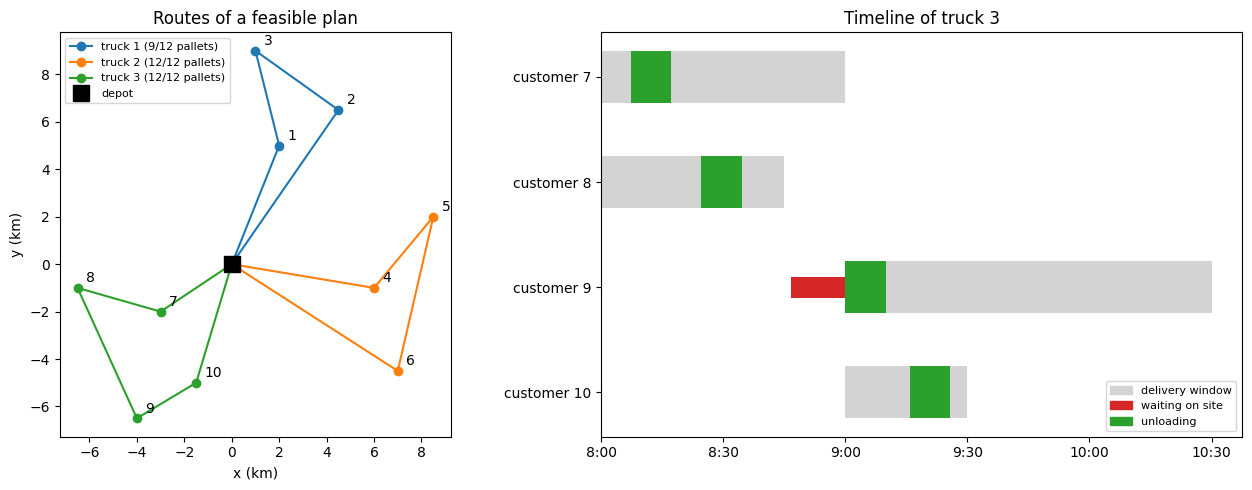

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np

# Depot (0) and 10 customers: coordinates in km, demand in pallets, window in minutes after 8:00
coords = np.array([[0, 0], [2, 5], [4.5, 6.5], [1, 9], [6, -1], [8.5, 2], [7, -4.5],
                   [-3, -2], [-6.5, -1], [-4, -6.5], [-1.5, -5]])
demand = [0, 3, 4, 2, 5, 3, 4, 2, 3, 4, 3]
window = {7: (0, 60), 8: (0, 45), 9: (60, 150), 10: (60, 90)}
routes = [[1, 3, 2], [4, 5, 6], [7, 8, 9, 10]]
colors = ["tab:blue", "tab:orange", "tab:green"]
SPEED, SERVICE = 0.5, 10  # 30 km/h = 0.5 km/min, 10 min unloading

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.3]})

# Left: routes on the map
for k, route in enumerate(routes):
    path = coords[[0, *route, 0]]
    load = sum(demand[c] for c in route)
    ax1.plot(path[:, 0], path[:, 1], "-o", color=colors[k], label=f"truck {k + 1} ({load}/12 pallets)")
ax1.plot(0, 0, "ks", ms=12, label="depot")
for i in range(1, 11):
    ax1.annotate(str(i), coords[i], xytext=(6, 4), textcoords="offset points")
ax1.set(title="Routes of a feasible plan", xlabel="x (km)", ylabel="y (km)", aspect="equal")
ax1.legend(loc="upper left", fontsize=8)

# Right: timeline of truck 3 (arrive, wait if early, unload)
clock, prev = 0.0, 0
for row, c in enumerate(routes[2]):
    arrival = clock + np.linalg.norm(coords[c] - coords[prev]) / SPEED
    start = max(arrival, window[c][0])
    a, b = window[c]
    ax2.barh(row, b - a, left=a, color="lightgray", height=0.5)
    if start > arrival:
        ax2.barh(row, start - arrival, left=arrival, color="tab:red", height=0.2)
    ax2.barh(row, SERVICE, left=start, color="tab:green", height=0.5)
    clock, prev = start + SERVICE, c
ax2.set_yticks(range(4), [f"customer {c}" for c in routes[2]])
ax2.set_xticks(range(0, 151, 30), ["8:00", "8:30", "9:00", "9:30", "10:00", "10:30"])
ax2.invert_yaxis()
ax2.set(title="Timeline of truck 3")
ax2.legend(handles=[Patch(color=c, label=l) for c, l in [("lightgray", "delivery window"), ("tab:red", "waiting on site"), ("tab:green", "unloading")]],
           loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()